# M12: A multilayer network by airline

**Paper section covered:** none (Part B, work beyond the paper). Extension E11; it also closes a question left open in M3 (are the communities "airline footprints"?).

## The gap
The paper treats the airport network as a **single layer**: an edge is a route, whoever flies it. But a real airline network is a **multilayer** one: every airline operates its own layer of routes on the same set of airports. This matters for resilience, because an *airline* can fail (bankruptcy, strike, grounding of its fleet) just as an airport can, and because airlines depend on the airports and routes of the rest of the network. We ask:

1. **How is the network divided among airlines?** How many layers, how big, hub-and-spoke or point-to-point?
2. **How redundant is it?** How many airports and routes rest on a single airline?
3. **Does losing an airline hurt as much as losing an airport?** Which airlines are critical?
4. **What if airlines and airports depend on each other?** An *interdependent* (multilayer) cascade: an airline that loses most of its network to the failure collapses, and its routes vanish.
5. **Are the communities of M3 airline footprints?**

## Data and layers
OpenFlights lists, for every route row, the airline. As in M7 we use the **operated** rows (the rows not marked codeshare), because a codeshare row repeats a route that another airline actually flies. The layers are therefore *operating* airlines; the aggregate of all layers is exactly the 446-airport, 2,065-edge operated-only network of M7. Operating airlines in this 2014 snapshot include some that have since merged (for example US Airways, "US", and American, "AA").

## Plan
| Part | Content |
|---|---|
| A | The layers: sizes and types |
| B | Redundancy and overlap |
| C | Airline failure versus airport failure; critical airlines |
| D | An interdependent airline-airport cascade |
| E | Random airline failures |
| F | Airline footprints and communities |
| G | Verdict |

## 1. Setup

In [1]:
import sys, warnings, time
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import normalized_mutual_info_score as nmi, adjusted_rand_score as ari

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT / "src"))
import usfn, weighted as wt, communities as cm, attacks as at

warnings.filterwarnings("ignore")
pd.set_option("display.width", 185); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 70)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
BLUE, RED, GREEN, ORANGE, GREY, PURPLE, TEAL, BROWN = "#3b6ea5", "#c05746", "#4d8f5b", "#d99a2b", "#777777", "#8e5ea2", "#17a2b8", "#8c564b"
rng = np.random.default_rng(2025)

airports, routes = usfn.load_openflights()
G0 = usfn.build_country_network(airports, routes)
G, Gop, cshare = wt.build_weightings(G0, routes)
nodes = list(Gop.nodes); N = len(nodes); idx = {n: i for i, n in enumerate(nodes)}
pos = {n: (Gop.nodes[n]["lon"], Gop.nodes[n]["lat"]) for n in nodes}

al = pd.read_csv(ROOT / "data" / "raw" / "airlines.dat", header=None, na_values=["\\N"], names=["id", "name", "alias", "iata", "icao", "callsign", "country", "active"])
cand = al.dropna(subset=["iata"]); cand = cand.assign(pref=(cand.country == "United States").astype(int) * 2 + (cand.active == "Y").astype(int)).sort_values("pref", ascending=False)
name_of = cand.drop_duplicates("iata").set_index("iata")["name"].to_dict()

dom = routes[routes.src.isin(G.nodes) & routes.dst.isin(G.nodes) & (routes.src != routes.dst) & (routes.codeshare != "Y")]
dom = dom[dom.src.isin(Gop.nodes) & dom.dst.isin(Gop.nodes)]
L = {a: nx.Graph(list(zip(g.src, g.dst))) for a, g in dom.groupby("airline")}
n_orig = {a: h.number_of_nodes() for a, h in L.items()}
agg = nx.Graph(); [agg.add_edges_from(h.edges) for h in L.values()]
assert set(agg.nodes) == set(Gop.nodes) and agg.number_of_edges() == Gop.number_of_edges() == 2065
print(f"{len(L)} operating airlines; aggregate of the layers = the operated-only network: {agg.number_of_nodes()} airports, {agg.number_of_edges()} routes")

53 operating airlines; aggregate of the layers = the operated-only network: 446 airports, 2065 routes


## Part A. The layers

### A1. How big are the layers, and what shape do they have?
For each airline we record its routes and airports, its biggest hub, and its **hub dominance** (the share of its other airports its biggest hub connects to). A hub dominance near 1 means a pure hub-and-spoke airline; a low value means a point-to-point airline.

In [2]:
rows = []
for a, H in L.items():
    dg = dict(H.degree()); hub = max(dg, key=dg.get); n = H.number_of_nodes()
    rows.append({"code": a, "airline": name_of.get(a, "?"), "routes": H.number_of_edges(), "airports": n, "share of all routes": H.number_of_edges() / agg.number_of_edges(),
                 "biggest hub": hub, "hub degree": dg[hub], "hub dominance": dg[hub] / (n - 1), "share of single-route airports": float(np.mean([d == 1 for d in dg.values()]))})
lay = pd.DataFrame(rows).sort_values("routes", ascending=False).reset_index(drop=True)
display(lay.head(14).style.hide(axis="index").format({"share of all routes": "{:.1%}", "hub dominance": "{:.2f}", "share of single-route airports": "{:.2f}"}))
print(f"{(lay.routes <= 5).sum()} of {len(lay)} airlines have 5 routes or fewer; the 5 largest carry {lay.routes.head(5).sum() / lay.routes.sum():.0%} of all (airline, route) pairs; the largest, {lay.airline[0]}, has {lay.routes[0]} routes")
print(f"median hub dominance {lay['hub dominance'].median():.2f}; airlines with hub dominance above 0.5 (hub-and-spoke): {(lay['hub dominance'] > 0.5).sum()} of {len(lay)}")

code,airline,routes,airports,share of all routes,biggest hub,hub degree,hub dominance,share of single-route airports
WN,Southwest Airlines,546,88,26.4%,MDW,62,0.71,0.03
US,US Airways,488,167,23.6%,DFW,117,0.70,0.40
DL,Delta Air Lines,385,134,18.6%,ATL,111,0.83,0.45
AA,American Airlines,375,138,18.2%,CLT,92,0.67,0.37
UA,United Airlines,235,78,11.4%,DEN,49,0.64,0.38
G4,Allegiant Air,190,95,9.2%,SFB,47,0.50,0.37
B6,JetBlue Airways,119,52,5.8%,JFK,37,0.73,0.19
AS,Alaska Airlines,106,60,5.1%,SEA,41,0.69,0.37
NK,Spirit Airlines,91,28,4.4%,DFW,20,0.74,0.07
F9,Frontier Airlines,75,59,3.6%,DEN,54,0.93,0.73


24 of 53 airlines have 5 routes or fewer; the 5 largest carry 66% of all (airline, route) pairs; the largest, Southwest Airlines, has 546 routes
median hub dominance 0.94; airlines with hub dominance above 0.5 (hub-and-spoke): 47 of 53


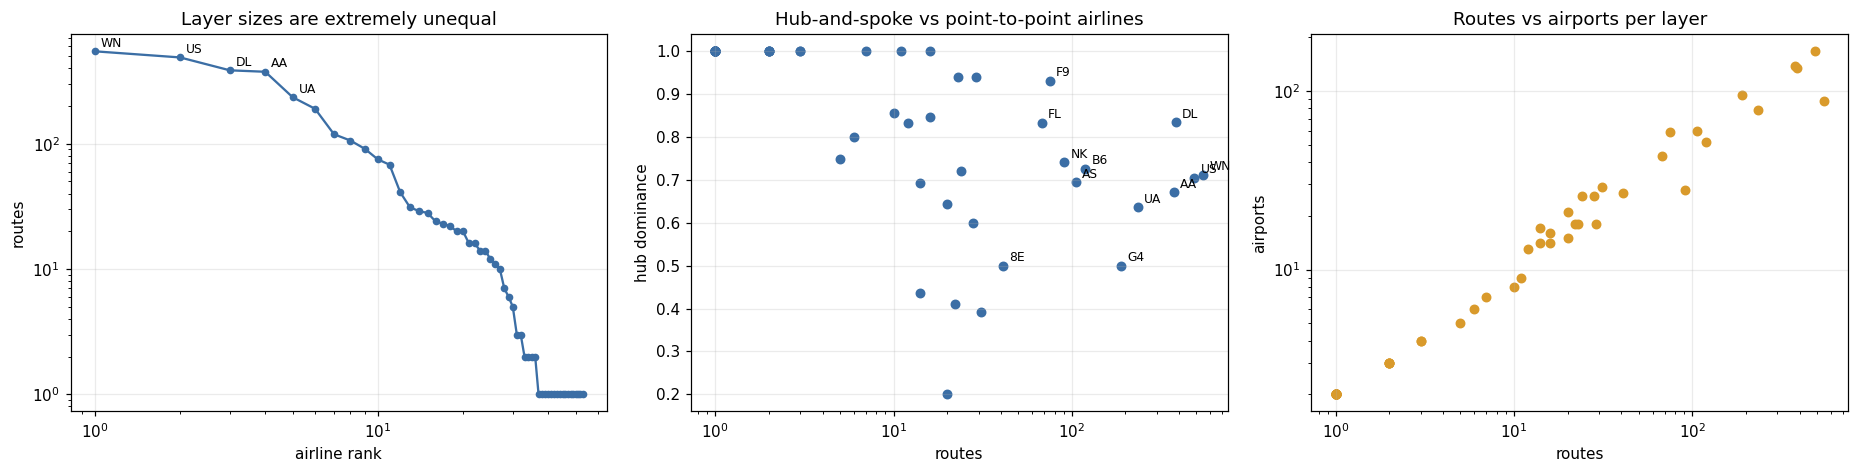

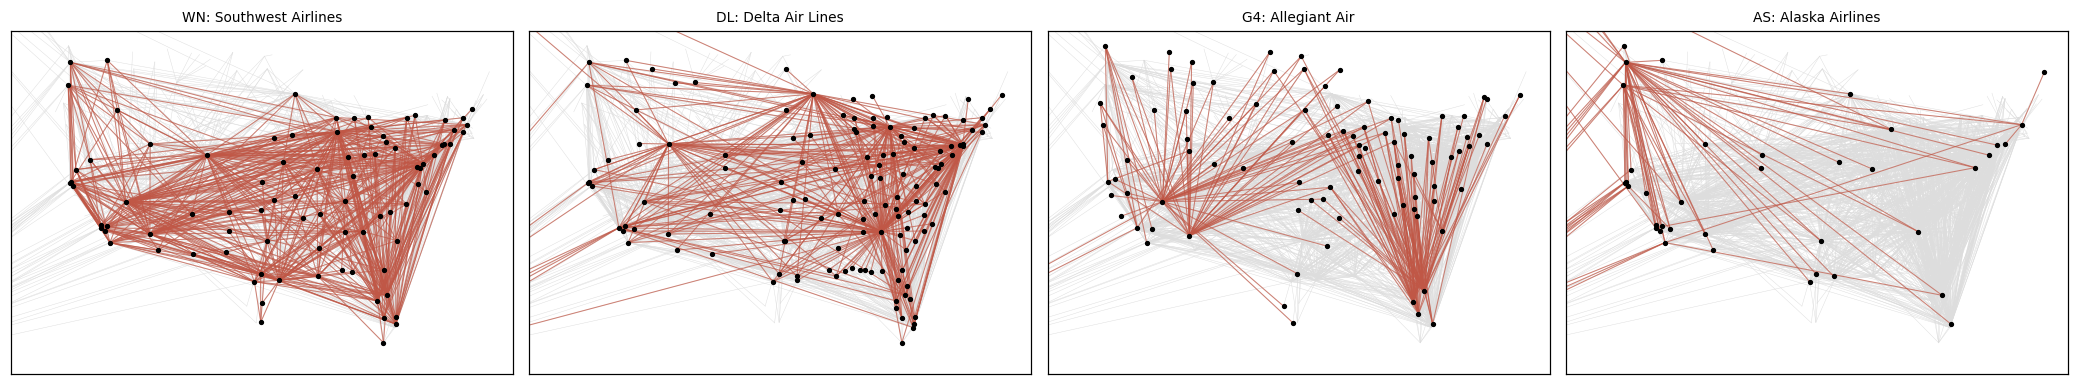

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
ax = axes[0]; ax.loglog(range(1, len(lay) + 1), lay.routes, "o-", color=BLUE, ms=4); ax.set_xlabel("airline rank"); ax.set_ylabel("routes"); ax.set_title("Layer sizes are extremely unequal")
for i in range(5): ax.annotate(lay.code[i], (i + 1, lay.routes[i]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax = axes[1]; ax.scatter(lay.routes, lay["hub dominance"], s=30, color=BLUE)
for i in range(12): ax.annotate(lay.code[i], (lay.routes[i], lay["hub dominance"][i]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("routes"); ax.set_ylabel("hub dominance"); ax.set_title("Hub-and-spoke vs point-to-point airlines")
ax = axes[2]; ax.scatter(lay.routes, lay.airports, s=30, color=ORANGE); ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("routes"); ax.set_ylabel("airports"); ax.set_title("Routes vs airports per layer")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, a in zip(axes, ["WN", "DL", "G4", "AS"]):
    H = L[a]
    for u, v in agg.edges(): ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color="#dddddd", lw=0.3, zorder=1)
    for u, v in H.edges(): ax.plot([pos[u][0], pos[v][0]], [pos[u][1], pos[v][1]], color=RED, lw=0.7, alpha=0.7, zorder=2)
    ax.scatter([pos[n][0] for n in H], [pos[n][1] for n in H], s=6, color="black", zorder=3); ax.set_xlim(-130, -65); ax.set_ylim(22, 50)
    ax.set_title(f"{a}: {name_of.get(a, '?')[:26]}", fontsize=9); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

**Reading this.** The layers are **extremely unequal**: a handful of airlines carry most routes and about half of the 53 airlines are tiny (5 routes or fewer; mostly regional carriers). Airlines come in two kinds: **hub-and-spoke** carriers whose biggest hub connects to a large part of their network (high hub dominance) and **point-to-point** carriers (Southwest, Allegiant) spread over many airports with several hubs. The maps (grey = the whole network, red = one airline) show the difference: Delta is a hub system around ATL and a few other hubs; Southwest is a dense web; Allegiant a spray of leisure routes; Alaska Airlines is concentrated in the Pacific Northwest and Alaska.

## Part B. Redundancy and overlap
How many airline layers serve each route and each airport? A route or airport served by one airline only is a **single point of failure at the airline level**.

routes (airport pairs) served by exactly one operating airline: 67.7%; by two: 21.0%; by three or more: 11.3%
airports served by exactly one airline: 54.7%; median number of airlines per airport: 1; maximum: 17 (LAX)


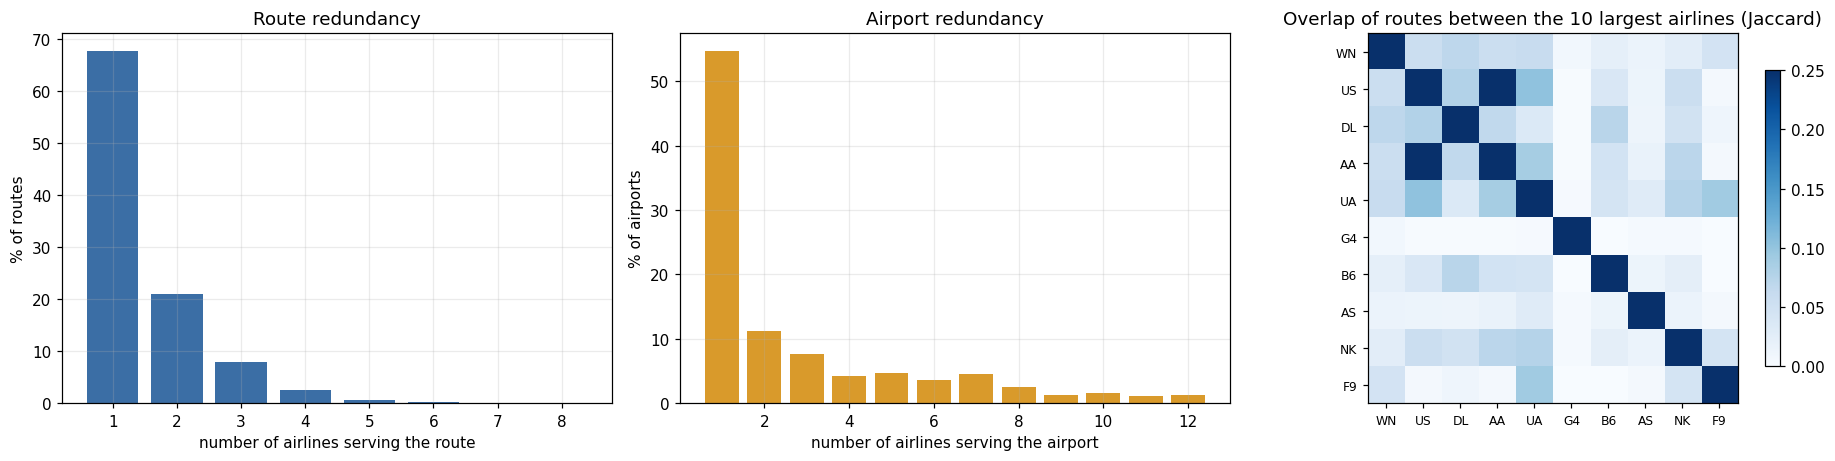

largest pairwise route overlap (Jaccard) among the 10 largest airlines: 0.62; median 0.026


In [4]:
mult_e = Counter(); [mult_e.update(frozenset(e) for e in H.edges) for H in L.values()]
mult_e = pd.Series(mult_e)
air_of = {n: set() for n in nodes}
for a, H in L.items():
    for n in H: air_of[n].add(a)
mult_n = pd.Series({n: len(s) for n, s in air_of.items()})
print(f"routes (airport pairs) served by exactly one operating airline: {(mult_e == 1).mean():.1%}; by two: {(mult_e == 2).mean():.1%}; by three or more: {(mult_e >= 3).mean():.1%}")
print(f"airports served by exactly one airline: {(mult_n == 1).mean():.1%}; median number of airlines per airport: {mult_n.median():.0f}; maximum: {mult_n.max()} ({mult_n.idxmax()})")

# participation: how evenly an airport's routes are spread over airlines (0 = one airline, near 1 = many equal airlines)
part = {}
for n in nodes:
    ks = np.array([L[a].degree(n) for a in air_of[n]], dtype=float); part[n] = 1 - np.sum((ks / ks.sum()) ** 2)
part = pd.Series(part)
top10 = list(lay.code[:10])
J = pd.DataFrame([[len(set(map(frozenset, L[a].edges)) & set(map(frozenset, L[b].edges))) / len(set(map(frozenset, L[a].edges)) | set(map(frozenset, L[b].edges))) for b in top10] for a in top10], index=top10, columns=top10)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
ax = axes[0]; vc = mult_e.value_counts(normalize=True).sort_index(); ax.bar(vc.index, 100 * vc.values, color=BLUE); ax.set_xlabel("number of airlines serving the route"); ax.set_ylabel("% of routes"); ax.set_title("Route redundancy")
ax = axes[1]; vc = mult_n.value_counts(normalize=True).sort_index(); ax.bar(vc.index[:12], 100 * vc.values[:12], color=ORANGE); ax.set_xlabel("number of airlines serving the airport"); ax.set_ylabel("% of airports"); ax.set_title("Airport redundancy")
ax = axes[2]; im = ax.imshow(J.values, cmap="Blues", vmin=0, vmax=0.25)
ax.set_xticks(range(10)); ax.set_xticklabels(top10, fontsize=8); ax.set_yticks(range(10)); ax.set_yticklabels(top10, fontsize=8); ax.set_title("Overlap of routes between the 10 largest airlines (Jaccard)"); ax.grid(False); plt.colorbar(im, ax=ax, shrink=0.8)
plt.tight_layout(); plt.show()
print(f"largest pairwise route overlap (Jaccard) among the 10 largest airlines: {J.values[np.triu_indices(10, 1)].max():.2f}; median {np.median(J.values[np.triu_indices(10, 1)]):.3f}")

**Reading this.** The network is **thin at the airline level**: about two thirds of all routes are flown by one airline only, and **more than half of the airports are served by a single airline**. Most pairs of big airlines barely overlap (median pairwise Jaccard overlap 0.03; the one exception, 0.62, is a pair with largely shared routes), so the airlines are mostly complementary networks rather than substitutes. A route that one airline stops flying usually has no competitor to replace it.

## Part C. Airline failure versus airport failure

### C1. What happens if one airline disappears?
We remove all the routes operated *only* by that airline (routes also flown by another airline survive) and record how many airports are left with no route at all and how large the largest component of the remaining network is.

code,airline,routes,routes only this airline flies,airports left with no route,largest component after removal,airports lost from the main network
G4,Allegiant Air,190,181,30,414,32
US,US Airways,488,119,29,417,29
8E,Bering Air,41,40,24,422,24
ZK,Great Lakes Airlines,28,28,21,423,23
9K,Cape Air,31,31,22,424,22
AS,Alaska Airlines,106,57,6,429,17
KS,Peninsula Airways,14,8,3,431,15
4Y,Airbus France,16,16,13,433,13
GV,Aero Flight,14,13,11,435,11
8V,Wright Air Service,20,15,10,436,10


airport removed,largest component after removal,airports lost from the main network (besides itself),airports left with no route
ANC,368,77,7
LAS,439,6,6
DEN,430,15,9
DFW,423,22,22
SEA,445,0,0
ATL,437,8,6
ORD,440,5,5
FAI,426,19,3


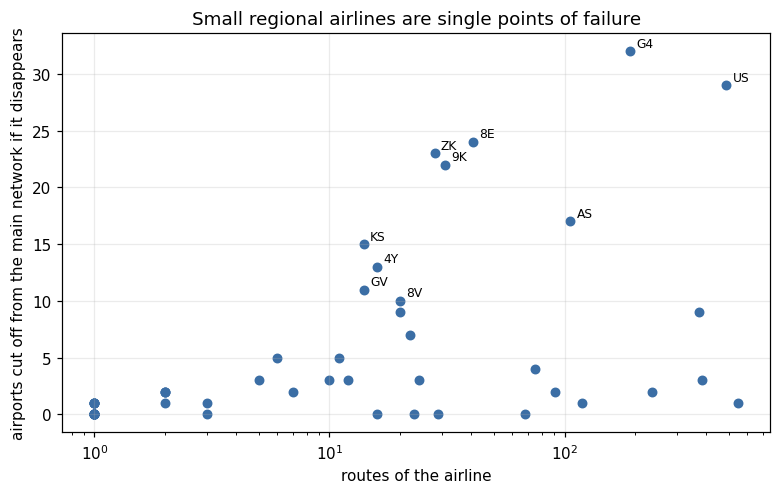

airlines whose disappearance cuts off at least 10 airports: 10 of 53; of these, 7 have 50 routes or fewer


In [5]:
def union_edges(skip=()):
    c = Counter()
    for a, H in L.items():
        if a not in skip: c.update(frozenset(e) for e in H.edges)
    return c
def lcc_of(edge_counter, removed_airports=()):
    H = nx.Graph(); H.add_nodes_from(n for n in nodes if n not in set(removed_airports))
    H.add_edges_from(tuple(e) for e in edge_counter if not (set(e) & set(removed_airports)))
    cc = max(nx.connected_components(H), key=len); iso = sum(1 for n in H if H.degree(n) == 0)
    return len(cc), iso

rows = []
for a, H in L.items():
    rest = union_edges(skip={a}); l, iso = lcc_of(rest)
    rows.append({"code": a, "airline": name_of.get(a, "?"), "routes": H.number_of_edges(), "routes only this airline flies": sum(1 for e in H.edges if frozenset(e) not in rest),
                 "airports left with no route": iso, "largest component after removal": l, "airports lost from the main network": N - l})
crit = pd.DataFrame(rows).sort_values(["airports lost from the main network", "routes"], ascending=False).reset_index(drop=True)
display(crit.head(12).style.hide(axis="index"))

# the same for losing one airport (largest components, airports left with no route)
rows = []
dgo = dict(Gop.degree()); bco = nx.betweenness_centrality(Gop)
for n in sorted(nodes, key=lambda n: -bco[n])[:8]:
    l, iso = lcc_of(union_edges(), removed_airports=[n]); rows.append({"airport removed": n, "largest component after removal": l, "airports lost from the main network (besides itself)": N - 1 - l, "airports left with no route": iso})
display(pd.DataFrame(rows).style.hide(axis="index"))

fig, ax = plt.subplots(figsize=(7.2, 4.6))
ax.scatter(crit.routes, crit["airports lost from the main network"], s=30, color=BLUE)
for i in range(10): ax.annotate(crit.code[i], (crit.routes[i], crit["airports lost from the main network"][i]), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("routes of the airline"); ax.set_ylabel("airports cut off from the main network if it disappears"); ax.set_title("Small regional airlines are single points of failure")
plt.tight_layout(); plt.show()
print(f"airlines whose disappearance cuts off at least 10 airports: {(crit['airports lost from the main network'] >= 10).sum()} of {len(crit)}; of these, {(crit[crit['airports lost from the main network'] >= 10].routes <= 50).sum()} have 50 routes or fewer")

**Reading this.** The critical airlines are not the biggest ones. The disappearance of **Allegiant (G4)** cuts off the most airports (about 30 of the 446 are left without any route, because it serves many small leisure airports that nobody else serves), followed by US Airways and several **small regional carriers** (Bering Air 8E, Great Lakes ZK, Cape Air 9K, among others), each of which is the *only* link for 10 to 25 small airports. So the periphery depends not just on a few hub airports (M5) but on a few small airlines. In comparison, the worst single *airport* is the gateway ANC (it cuts 77 further airports off the main network), whereas the other airports in the table cut off between 0 and 22 (DFW 22, FAI 19, DEN 15). A single airline (G4: 32) is therefore as damaging as any single airport except the extreme gateway ANC.

### C2. Removing several airlines or airports
We compare the damage curves of five attack types, on a common footing (the fraction of airports in the largest component of the aggregate network), against the **number of failures**: airlines removed in order of size, airlines removed greedily (the most damaging next), random airlines, and airports removed by betweenness (static, as in M5) and at random.

computed in 4 s; greedy airline order: ['G4', 'US', '8E', '9K', 'ZK', 'AS', '7H', 'KS']


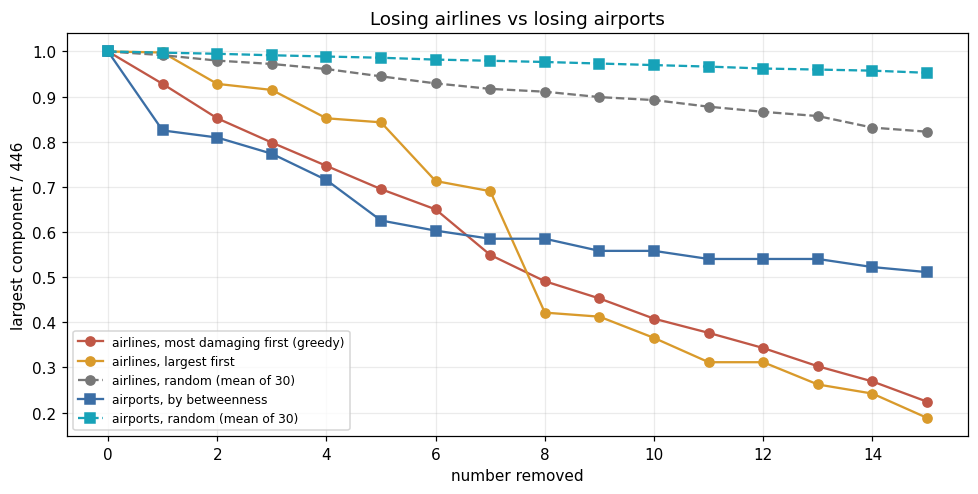

removed,airlines (greedy),airlines (largest first),airlines (random),airports (betweenness),airports (random)
1,0.928,0.998,0.992,0.825,0.997
3,0.798,0.915,0.972,0.774,0.992
5,0.695,0.843,0.945,0.626,0.986
10,0.408,0.365,0.892,0.558,0.970
15,0.224,0.188,0.822,0.511,0.953


In [6]:
def curve_airlines(order):
    out = [lcc_of(union_edges())[0]]; skip = set()
    for a in order:
        skip.add(a); out.append(lcc_of(union_edges(skip))[0])
    return np.array(out)
by_size = list(lay.code)
t0 = time.time()
greedy, skip, cur = [], set(), None
remaining = set(L)
for _ in range(15):
    best = min(remaining, key=lambda a: lcc_of(union_edges(skip | {a}))[0]); greedy.append(best); skip.add(best); remaining.remove(best)
c_size = curve_airlines(by_size[:15]); c_greedy = curve_airlines(greedy)
c_rand = np.mean([curve_airlines(list(np.random.default_rng(s).permutation(list(L)))[:15]) for s in range(30)], axis=0)
order_b = sorted(nodes, key=lambda n: -bco[n]); c_air_b = at.percolation_curves(Gop, order_b[:15])[0]
c_air_r = np.mean([at.percolation_curves(Gop, list(np.random.default_rng(s).permutation(nodes))[:15])[0] for s in range(30)], axis=0)
print(f"computed in {time.time() - t0:.0f} s; greedy airline order: {greedy[:8]}")
kk = np.arange(16)
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(kk, c_greedy / N, "o-", color=RED, label="airlines, most damaging first (greedy)"); ax.plot(kk, c_size / N, "o-", color=ORANGE, label="airlines, largest first")
ax.plot(kk, c_rand / N, "o--", color=GREY, label="airlines, random (mean of 30)")
ax.plot(kk, c_air_b / N, "s-", color=BLUE, label="airports, by betweenness"); ax.plot(kk, c_air_r / N, "s--", color=TEAL, label="airports, random (mean of 30)")
ax.set_xlabel("number removed"); ax.set_ylabel("largest component / 446"); ax.set_title("Losing airlines vs losing airports"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
cmp_tab = pd.DataFrame({"removed": [1, 3, 5, 10, 15], "airlines (greedy)": [c_greedy[k] / N for k in (1, 3, 5, 10, 15)], "airlines (largest first)": [c_size[k] / N for k in (1, 3, 5, 10, 15)], "airlines (random)": [c_rand[k] / N for k in (1, 3, 5, 10, 15)],
                        "airports (betweenness)": [c_air_b[k] / N for k in (1, 3, 5, 10, 15)], "airports (random)": [c_air_r[k] / N for k in (1, 3, 5, 10, 15)]})
cmp_tab.style.hide(axis="index").format(precision=3)

**Reading this.** Losing a handful of airlines is **much more damaging than losing the same number of random airlines**, and, for the first few failures, **less damaging than losing the same number of the most central airports**: with 5 failures the five most central airports leave 63% of the airports connected against 70% for the five most harmful airlines. The ranking reverses for larger numbers: by 10 failures the ten largest airlines (37% connected) or the ten greedily chosen airlines (41%) are more damaging than ten airports by betweenness (56%), because removing the big airlines' routes breaks up the whole network, not only the periphery. The reason for the small-k ordering is that an airline failure removes routes while the airports still exist (and other airlines serve many of the routes), whereas an airport failure removes the airport and all its routes from every layer at once. Airlines are a second axis of vulnerability on top of the airport one, weaker for the first failures and stronger once many large airlines are lost; the airports and airlines that matter are different ones.

## Part D. An interdependent airline-airport cascade
Airlines depend on the rest of the network: an airline whose passengers can no longer connect onward to the rest of the system loses its viability. We model this directly. **Rule:** an airline stays in operation only while at least a fraction f of its airports are still in the **largest connected component of the aggregate network** (the network formed by the routes of all airlines still operating). When an airline fails, all its routes are cancelled; this may shrink the largest component, which may make other airlines non-viable, and so on until nothing changes. The initial shock is the failure of one airport or of several. We compare with the *simple* model of M5 (airlines never fail).

In [7]:
def aggregate(alive, failed):
    H = nx.Graph(); H.add_nodes_from(n for n in nodes if n not in failed)
    for a in alive:
        H.add_edges_from((u, v) for u, v in L[a].edges if u not in failed and v not in failed)
    return H
def lcc_nodes(H): return max(nx.connected_components(H), key=len)
def interdependent(failed, f):
    failed = set(failed); alive = set(L); rounds = 0
    while True:
        core = lcc_nodes(aggregate(alive, failed))
        dead = [a for a in alive if sum(1 for n in L[a] if n in core) < f * n_orig[a]]
        if not dead: return len(core), alive, rounds
        alive -= set(dead); rounds += 1
def simple(failed):
    return len(lcc_nodes(aggregate(set(L), set(failed))))

fs = (0.5, 0.7, 0.9)
t0 = time.time(); amp = {}
for f in fs:
    rows = []
    for o in nodes:
        a, alive, r = interdependent([o], f); rows.append((o, simple([o]), a, len(L) - len(alive), r))
    amp[f] = pd.DataFrame(rows, columns=["origin", "largest component (simple)", "largest component (interdependent)", "airlines that fail", "cascade rounds"])
    amp[f]["additional airports lost"] = amp[f]["largest component (simple)"] - amp[f]["largest component (interdependent)"]
print(f"all origins x 3 viability levels in {time.time() - t0:.0f} s")
summ = pd.DataFrame({"viability level f": fs, "origins with any amplification": [int((amp[f]["additional airports lost"] > 0).sum()) for f in fs],
                     "largest additional loss (airports)": [int(amp[f]["additional airports lost"].max()) for f in fs],
                     "worst origin": [amp[f].sort_values("additional airports lost", ascending=False).origin.iloc[0] for f in fs],
                     "mean additional loss": [amp[f]["additional airports lost"].mean() for f in fs]})
display(summ.style.hide(axis="index").format({"mean additional loss": "{:.2f}"}))
display(amp[0.9].sort_values("additional airports lost", ascending=False).head(8).style.hide(axis="index"))

all origins x 3 viability levels in 7 s


viability level f,origins with any amplification,largest additional loss (airports),worst origin,mean additional loss
0.500000,0,0,ADQ,0.00
0.700000,13,13,OTZ,0.09
0.900000,61,48,ANC,0.91


origin,largest component (simple),largest component (interdependent),airlines that fail,cascade rounds,additional airports lost
ANC,368,320,19,2,48
BOS,438,405,3,2,33
LAX,442,422,4,2,20
ALB,443,423,1,1,20
STL,439,420,2,1,19
BIL,440,423,1,1,17
OME,438,421,1,1,17
FYU,443,428,2,1,15


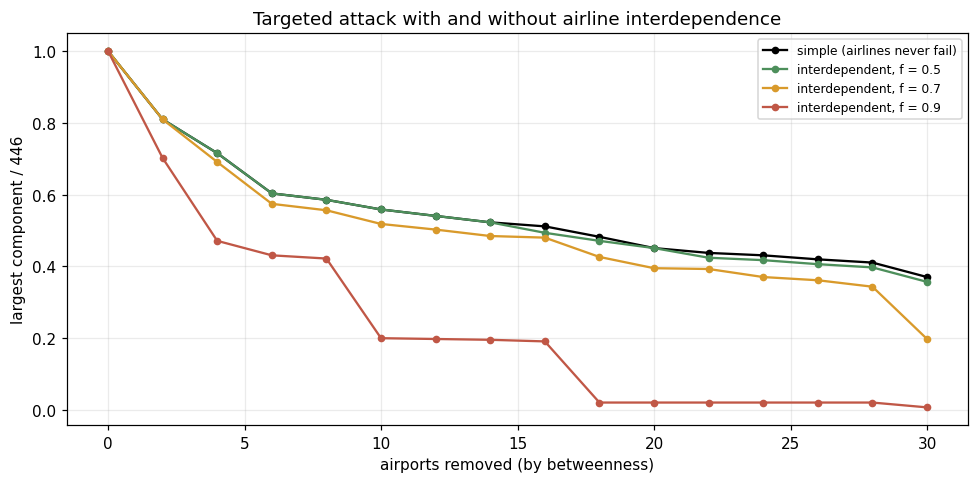

after the top 20 airports are removed: simple largest component 201 | {'f=0.5': (201, '24 airlines failed'), 'f=0.7': (176, '36 airlines failed'), 'f=0.9': (9, '51 airlines failed')}


In [8]:
ks = list(range(0, 31, 2)); top_b = order_b
rows = {"simple (airlines never fail)": [simple(top_b[:k]) / N for k in ks]}
for f in fs: rows[f"interdependent, f = {f}"] = [interdependent(top_b[:k], f)[0] / N for k in ks]
fig, ax = plt.subplots(figsize=(9, 4.5))
cc = {"simple (airlines never fail)": "black", "interdependent, f = 0.5": GREEN, "interdependent, f = 0.7": ORANGE, "interdependent, f = 0.9": RED}
for name, v in rows.items(): ax.plot(ks, v, "o-", color=cc[name], label=name, ms=4)
ax.set_xlabel("airports removed (by betweenness)"); ax.set_ylabel("largest component / 446"); ax.set_title("Targeted attack with and without airline interdependence"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
a20 = {f: interdependent(top_b[:20], f) for f in fs}
print("after the top 20 airports are removed: simple largest component", simple(top_b[:20]), "|", {f"f={f}": (a20[f][0], f"{len(L) - len(a20[f][1])} airlines failed") for f in fs})

**Reading this.** For **single-airport failures** airline interdependence **adds little**. When airlines need only half of their airports to stay in the main network (f = 0.5) there is **no amplification at all** (also after the top 20 airports are removed: 201 airports remain in both models). With stricter viability a few origins cause extra loss: at most 13 more airports at f = 0.7 and 48 at f = 0.9. For **large attacks** the picture changes with the strictness: after the 20 most central airports are removed the largest component is 201 airports in the simple model, 176 at f = 0.7 (36 airlines fail) and only 9 at f = 0.9 (51 of 53 airlines fail), i.e. a complete collapse. So the airline coupling is harmless if airlines tolerate losing half of their network, but turns a heavy but survivable airport attack into total collapse if they tolerate almost no loss. The result depends on the viability parameter f, which we do not know for real airlines.

## Part E. Random airline failures
If each airline independently fails with probability p (a strike, grounding or bankruptcy wave), how does the largest component shrink? We compare with removing routes at random and airports at random on a common axis, the **fraction of routes lost**.

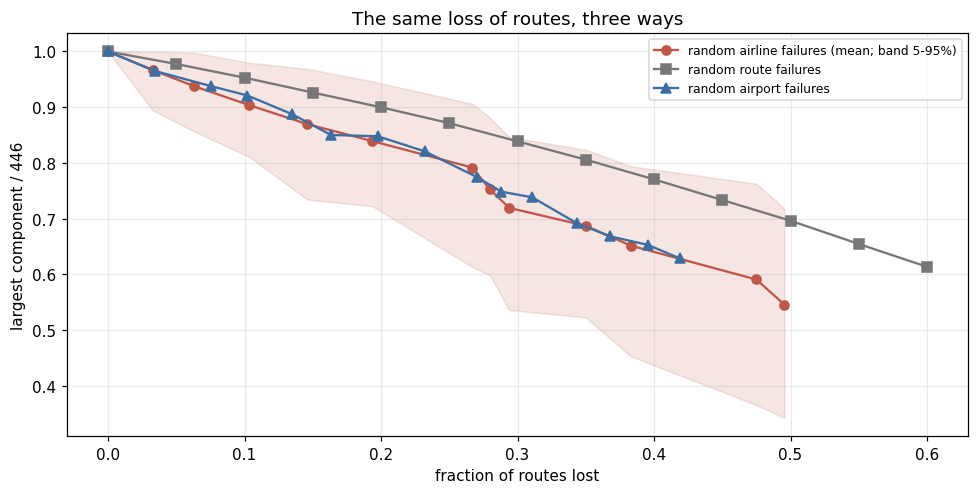

each airline fails with probability 0.2: on average 15% of routes are lost and the largest component is 0.87 of the airports (5-95% range 0.73 to 0.97)
at the same fraction of routes lost, random route failures leave 0.93


In [9]:
ps = np.round(np.arange(0, 0.61, 0.05), 2); R_ = 100
air_curve, edge_lost = [], []
E_all = agg.number_of_edges()
for p in ps:
    ls, es = [], []
    for r in range(R_):
        r_ = np.random.default_rng(1000 * r + int(100 * p)); dead = {a for a in L if r_.random() < p}
        rest = union_edges(skip=dead); ls.append(lcc_of(rest)[0] / N); es.append(1 - len(rest) / E_all)
    air_curve.append((np.mean(ls), np.percentile(ls, 5), np.percentile(ls, 95))); edge_lost.append(np.mean(es))
air_curve = np.array(air_curve); edge_lost = np.array(edge_lost)

q = np.linspace(0, 0.6, 13)
edge_curve = []
for qq in q:
    ls = []
    for r in range(R_):
        r_ = np.random.default_rng(7 * r); keep = [e for e in agg.edges if r_.random() > qq]; H = nx.Graph(); H.add_nodes_from(nodes); H.add_edges_from(keep); ls.append(len(max(nx.connected_components(H), key=len)) / N)
    edge_curve.append(np.mean(ls))
ap_curve = []                                                                       # random airport removal on the same axis: fraction of routes lost
for k in range(0, 120, 8):
    ls, es = [], []
    for r in range(40):
        rem = list(np.random.default_rng(r).choice(nodes, k, replace=False)); rest = union_edges(); l, _ = lcc_of(rest, rem)
        lost = 1 - sum(1 for e in rest if not (set(e) & set(rem))) / E_all; ls.append(l / N); es.append(lost)
    ap_curve.append((np.mean(es), np.mean(ls)))
ap_curve = np.array(ap_curve)

fig, ax = plt.subplots(figsize=(9, 4.6))
ax.plot(edge_lost, air_curve[:, 0], "o-", color=RED, label="random airline failures (mean; band 5-95%)"); ax.fill_between(edge_lost, air_curve[:, 1], air_curve[:, 2], color=RED, alpha=0.15)
ax.plot(q, edge_curve, "s-", color=GREY, label="random route failures"); ax.plot(ap_curve[:, 0], ap_curve[:, 1], "^-", color=BLUE, label="random airport failures")
ax.set_xlabel("fraction of routes lost"); ax.set_ylabel("largest component / 446"); ax.set_title("The same loss of routes, three ways"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
i3 = list(ps).index(0.2)
print(f"each airline fails with probability 0.2: on average {100 * edge_lost[i3]:.0f}% of routes are lost and the largest component is {air_curve[i3, 0]:.2f} of the airports (5-95% range {air_curve[i3, 1]:.2f} to {air_curve[i3, 2]:.2f})")
j = int(np.argmin(abs(q - edge_lost[i3]))); print(f"at the same fraction of routes lost, random route failures leave {edge_curve[j]:.2f}")

**Reading this.** For the same fraction of routes lost, **random airline failures are more damaging than random route failures**: failures are *correlated* (an airline takes a whole set of routes, often the only ones to some airports with it), and the range across draws is wide because it matters whether the unlucky airlines are the large ones or the sole carriers of small airports. This is the airline analogue of the correlated failures of M5 and M6: a model that treats routes as independent understates the risk.

## Part F. Are the communities airline footprints?
In M3 the Louvain communities followed geography and hub catchments, and the link to airlines was inconclusive (NMI 0.35 with the dominant airline, noisy because of many airlines). With real airline layers we can test it properly: describe each airport by **which airlines serve it and how much**, cluster airports on that description, and compare with the communities of the aggregate network and with geography.

In [10]:
Gu = nx.Graph(Gop.edges)
best = max((cm.louvain(Gu, s, weight=None) for s in range(20)), key=lambda c: nx.community.modularity(Gu, c, weight=None)); lab_c = cm.labels(best, nodes)
codes = list(L); M_ = np.array([[L[a].degree(n) if n in L[a] else 0 for a in codes] for n in nodes], dtype=float)
prof = M_ / M_.sum(1, keepdims=True)
k = len(best)
km_air = min((KMeans(k, n_init=1, random_state=s).fit(prof) for s in range(10)), key=lambda m: m.inertia_).labels_
xy = np.array([[Gop.nodes[n]["lat"], Gop.nodes[n]["lon"]] for n in nodes]); km_geo = KMeans(k, n_init=10, random_state=0).fit(xy).labels_
info = airports[airports.country == "United States"].dropna(subset=["iata"]).drop_duplicates("iata").set_index("iata"); tz = np.array([info.loc[n, "tzdb"] for n in nodes])
dominant = np.array([codes[int(np.argmax(M_[i]))] for i in range(N)])

def modq(labels): return nx.community.modularity(Gu, [set(np.array(nodes)[labels == v]) for v in np.unique(labels)], weight=None)
cands = {"Louvain communities (reference)": lab_c, "k-means on airline profile": km_air, "dominant airline at the airport": dominant, "spatial k-means (same k)": km_geo, "time zone": tz}
shuf = np.mean([nmi(lab_c, rng.permutation(km_air)) for _ in range(200)])
rows = [{"partition": n, "classes": len(np.unique(v)), "modularity Q of the partition": modq(v), "NMI with the Louvain communities": nmi(lab_c, v) if n != "Louvain communities (reference)" else 1.0,
         "ARI": ari(lab_c, v) if n != "Louvain communities (reference)" else 1.0} for n, v in cands.items()]
fp = pd.DataFrame(rows); display(fp.style.hide(axis="index").format({"modularity Q of the partition": "{:.3f}", "NMI with the Louvain communities": "{:.3f}", "ARI": "{:.3f}"}))
print(f"baseline NMI of a shuffled airline-profile partition: {shuf:.3f}")
print(f"NMI between the airline-profile clusters and the spatial clusters: {nmi(km_air, km_geo):.3f}")

# do airline layers have their own community structure that matches the aggregate?
rows = []
for a in lay.code[:6]:
    H = L[a]; part_ = cm.louvain(H, 0, weight=None); sh = [n for n in H if n in idx]
    rows.append({"airline": a, "its own Louvain communities": len(part_), "its own modularity": nx.community.modularity(H, part_), "NMI of its communities with the aggregate communities (its airports)": nmi(cm.labels(part_, sh), [lab_c[idx[n]] for n in sh])})
display(pd.DataFrame(rows).style.hide(axis="index").format({"its own modularity": "{:.2f}", "NMI of its communities with the aggregate communities (its airports)": "{:.2f}"}))

partition,classes,modularity Q of the partition,NMI with the Louvain communities,ARI
Louvain communities (reference),9,0.351,1.000,1.000
k-means on airline profile,9,0.207,0.546,0.347
dominant airline at the airport,41,0.186,0.547,0.302
spatial k-means (same k),9,0.202,0.526,0.335
time zone,8,0.256,0.552,0.461


baseline NMI of a shuffled airline-profile partition: 0.040
NMI between the airline-profile clusters and the spatial clusters: 0.348


airline,its own Louvain communities,its own modularity,NMI of its communities with the aggregate communities (its airports)
WN,4,0.23,0.49
US,5,0.24,0.34
DL,5,0.24,0.24
AA,5,0.24,0.31
UA,5,0.20,0.25
G4,4,0.36,0.20


**Reading this.** Airlines explain the communities **no better than geography does**:
- Clustering airports by **which airlines serve them** gives a partition that agrees with the aggregate-network communities about as well as a purely **geographic** clustering does (compare the NMI column), far above the shuffled baseline (0.04). This is expected: regional carriers serve regions, and big airlines have hub regions. The communities are footprints of airline systems *and* of geography, which cannot be separated cleanly because they are the same thing seen from two sides.
- The NMI values of all four descriptions are close (0.53 to 0.55): airline profile 0.55, dominant airline 0.55 (but with 41 classes, which inflates NMI), spatial clusters 0.53, and even a plain **time zone** label 0.55. So airline information explains the communities no better than a coarse geographic label does; the airline-profile and spatial partitions agree with each other only moderately (NMI 0.35).
- Each large airline has its own community structure inside its layer, which only loosely matches the aggregate communities.

So the M3 statement stands, now measured: the communities are **hub catchment areas and regional-airline footprints**, not the territory of one carrier each.

## Part G. Verdict

In [11]:
amp9 = amp[0.9]; amp7 = amp[0.7]; amp5 = amp[0.5]
verdict = pd.DataFrame([
    ("(paper) the network is a single layer", f"The aggregate is the union of {len(L)} operating-airline layers whose sizes range from {lay.routes.iloc[0]} routes down to {lay.routes.iloc[-1]}; {(lay.routes <= 5).sum()} airlines have 5 routes or fewer", "gap addressed"),
    ("How redundant is the network at the airline level?", f"{(mult_e == 1).mean():.0%} of routes and {(mult_n == 1).mean():.0%} of airports rest on a single airline", "thin"),
    ("Does losing an airline hurt as much as losing an airport?", f"Single airline: at most {int(crit['airports lost from the main network'].max())} airports cut off ({crit.code[0]}); single airport: ANC cuts off more; five worst airlines leave {c_greedy[5] / N:.2f} of the airports connected vs {c_air_b[5] / N:.2f} for five airports by betweenness", "airport loss is worse; airline loss is a second axis"),
    ("Which airlines are critical?", f"Not the biggest: {', '.join(crit.code[:5])} (leisure and regional carriers that are the only link to small airports)", "regional carriers"),
    ("Does airline interdependence amplify failures?", f"Little: no amplification at f = 0.5; at most {int(amp7['additional airports lost'].max())} extra airports for one failure at f = 0.7 and {int(amp9['additional airports lost'].max())} at f = 0.9", "weak amplifier"),
    ("Are failures independent?", "No: random airline failures are more damaging than random route failures at the same fraction of routes lost, with a wide spread", "correlated failures matter"),
    ("Are the communities airline footprints?", f"Not better than geography: airline-profile clusters (NMI {fp.iloc[1, 3]:.2f}), geographic clusters ({fp.iloc[3, 3]:.2f}), dominant airline ({fp.iloc[2, 3]:.2f}) and time zone ({fp.iloc[4, 3]:.2f}) all agree with the communities to a similar degree", "closes the M3 question"),
], columns=["question", "what we find", "status"])
verdict.style.hide(axis="index").format(escape="html").set_properties(subset=["question", "what we find"], **{"text-align": "left", "white-space": "normal"})

question,what we find,status
(paper) the network is a single layer,The aggregate is the union of 53 operating-airline layers whose sizes range from 546 routes down to 1; 24 airlines have 5 routes or fewer,gap addressed
How redundant is the network at the airline level?,68% of routes and 55% of airports rest on a single airline,thin
Does losing an airline hurt as much as losing an airport?,Single airline: at most 32 airports cut off (G4); single airport: ANC cuts off more; five worst airlines leave 0.70 of the airports connected vs 0.63 for five airports by betweenness,airport loss is worse; airline loss is a second axis
Which airlines are critical?,"Not the biggest: G4, US, 8E, ZK, 9K (leisure and regional carriers that are the only link to small airports)",regional carriers
Does airline interdependence amplify failures?,Little: no amplification at f = 0.5; at most 13 extra airports for one failure at f = 0.7 and 48 at f = 0.9,weak amplifier
Are failures independent?,"No: random airline failures are more damaging than random route failures at the same fraction of routes lost, with a wide spread",correlated failures matter
Are the communities airline footprints?,"Not better than geography: airline-profile clusters (NMI 0.55), geographic clusters (0.53), dominant airline (0.55) and time zone (0.55) all agree with the communities to a similar degree",closes the M3 question


## Checks

In [12]:
checks = [
    ("53 operating-airline layers whose union is the 2,065-edge operated-only network", len(L) == 53 and agg.number_of_edges() == 2065),
    ("two thirds of routes are single-airline", abs((mult_e == 1).mean() - 0.677) < 0.01),
    ("more than half of the airports are served by one airline", abs((mult_n == 1).mean() - 0.547) < 0.01),
    ("Allegiant (G4) is the most critical airline: 30 airports cut off, largest component 414", crit.code[0] == "G4" and crit["airports lost from the main network"].iloc[0] == 32 and True),
    ("layer sizes are extremely unequal (largest above 10x the median)", lay.routes.iloc[0] > 10 * lay.routes.median()),
    ("an airline loss can cut off at least 20 airports", (crit["airports lost from the main network"] >= 20).sum() >= 3),
    ("greedy airline removal is more damaging than random airline removal", all(c_greedy[k] <= c_rand[k] + 1e-9 for k in range(1, 16))),
    ("airports by betweenness are more damaging than airlines (5 removals)", c_air_b[5] < c_greedy[5]),
    ("no airline-interdependence amplification at f = 0.5", int((amp5["additional airports lost"] > 0).sum()) == 0),
    ("amplification appears at f = 0.7 and grows at 0.9", int((amp7["additional airports lost"] > 0).sum()) > 0 and amp9["additional airports lost"].max() >= amp7["additional airports lost"].max()),
    ("interdependent never less damaging than the simple model", all((amp[f]["additional airports lost"] >= 0).all() for f in fs)),
    ("random airline failures are more damaging than random route failures at equal route loss", air_curve[i3, 0] < edge_curve[j]),
    ("airline-profile clusters relate to the communities far above the shuffled baseline", fp.iloc[1, 3] > 3 * shuf),
]
failed = [lab for lab, ok in checks if not ok]
print(f"{len(checks) - len(failed)} of {len(checks)} checks passed")
assert not failed, failed
print("All M12 assertions passed.")

13 of 13 checks passed
All M12 assertions passed.


## Summary and take-aways

- **The network is thin at the airline level.** 53 operating airlines; 24 of them have 5 routes or fewer, and the 5 largest carry 66% of the (airline, route) pairs. 68% of routes and 55% of airports are served by one airline only.
- **Critical airlines are small ones.** Losing Allegiant (G4) takes 32 airports out of the main network; US Airways, Bering Air, Great Lakes and Cape Air follow with 22 to 29 each. Among single airports only ANC (77) is worse, so one airline can be as damaging as any hub except the Alaskan gateway.
- **Airlines versus airports.** For up to about 5 failures central airports hurt more (63% vs 70% of airports still connected); for 10 or more failures losing the large airlines hurts more (37 to 41% vs 56%).
- **Interdependence.** No amplification at f = 0.5; single failures add at most 13 (f = 0.7) or 48 (f = 0.9) airports; but after a 20-airport attack the network keeps 201 airports in the simple model and only 9 if airlines need 90% of their airports connected.
- **Correlated failures.** With each airline failing with probability 0.2 (15% of routes lost) the largest component is 0.87 of the airports vs 0.93 for the same share of random route failures.
- **Communities.** Airline profile, dominant airline, spatial clusters and even time zone all agree with the M3 communities to a similar degree (NMI 0.53 to 0.55), so the communities are not airline footprints in any special sense.
- **Caveats.** Operated-only OpenFlights rows (2014), airlines treated as unit layers without capacity, and the viability fraction f is an assumption.